# ASSIGNMENT No: 10

## Implement Page Rank Algorithm

**Problem Statement:** Implement Page Rank Algorithm using Python / NetworkX.

### Learning Objective
Learn to implement the PageRank algorithm and calculate the centrality/importance of nodes in a directed graph.

### Theory
PageRank is an algorithm originally developed for ranking web pages. It measures the importance of a page based on the number and quality of incoming links. The PageRank value is repeatedly updated until the values converge.

The damping factor is commonly set to **0.85**. The PageRank values form a probability distribution, so their sum is approximately 1.

This practical follows the PageRank approach described in the supplied laboratory manual.

In [1]:
# Step 1: Import required libraries

import networkx as nx
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


## Step 2: Create a directed graph

We create a small web-like graph with six pages. A directed edge `A -> B` means page A contains a link to page B.

In [2]:
# Create a directed graph

G = nx.DiGraph()

G.add_edges_from([
    ("A", "B"),
    ("A", "C"),
    ("B", "C"),
    ("B", "D"),
    ("C", "A"),
    ("C", "D"),
    ("D", "C"),
    ("D", "E"),
    ("E", "D"),
    ("E", "F"),
    ("F", "C")
])

print("Nodes:", list(G.nodes()))
print("Edges:", list(G.edges()))

Nodes: ['A', 'B', 'C', 'D', 'E', 'F']
Edges: [('A', 'B'), ('A', 'C'), ('B', 'C'), ('B', 'D'), ('C', 'A'), ('C', 'D'), ('D', 'C'), ('D', 'E'), ('E', 'D'), ('E', 'F'), ('F', 'C')]


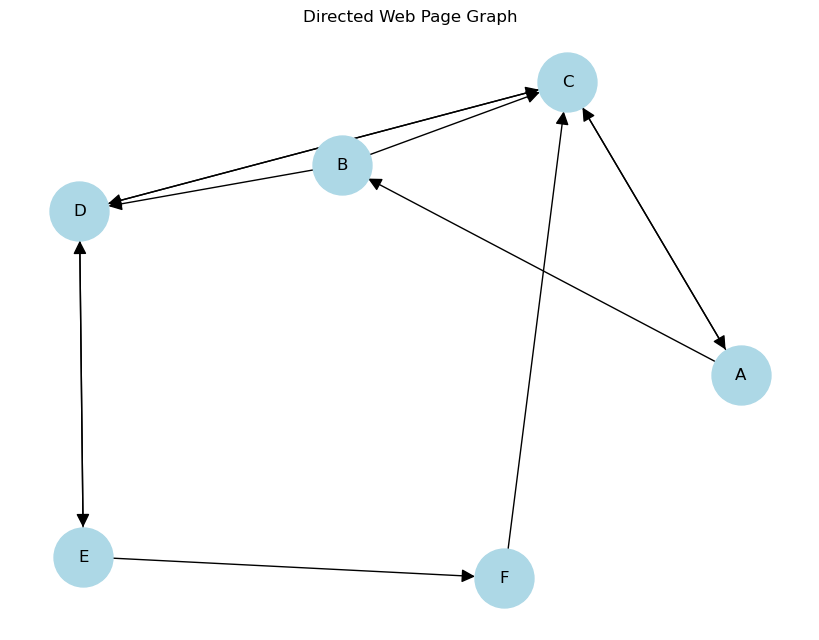

In [3]:
# Visualize the graph

plt.figure(figsize=(8, 6))
pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=1800,
    node_color="lightblue",
    arrows=True,
    arrowsize=20,
    font_size=12
)

plt.title("Directed Web Page Graph")
plt.show()

## Step 3: Calculate PageRank

NetworkX provides the PageRank implementation through `nx.pagerank()`.

Parameters used:
- **alpha = 0.85** — damping factor
- **max_iter = 100** — maximum number of iterations
- **tol = 1e-6** — convergence tolerance

In [4]:
# Calculate PageRank

pr = nx.pagerank(
    G,
    alpha=0.85,
    max_iter=100,
    tol=1.0e-6
)

print("PageRank values:")
for page, score in pr.items():
    print(f"{page}: {score:.6f}")

PageRank values:
A: 0.152928
B: 0.089995
C: 0.301009
D: 0.246286
E: 0.129672
F: 0.080110


In [5]:
# Display PageRank values in descending order

ranked_pages = sorted(pr.items(), key=lambda x: x[1], reverse=True)

print("Pages ranked according to PageRank:")
for rank, (page, score) in enumerate(ranked_pages, start=1):
    print(f"{rank}. Page {page} -> {score:.6f}")

print("\nSum of PageRank values:", sum(pr.values()))

Pages ranked according to PageRank:
1. Page C -> 0.301009
2. Page D -> 0.246286
3. Page A -> 0.152928
4. Page E -> 0.129672
5. Page B -> 0.089995
6. Page F -> 0.080110

Sum of PageRank values: 0.9999999999999999


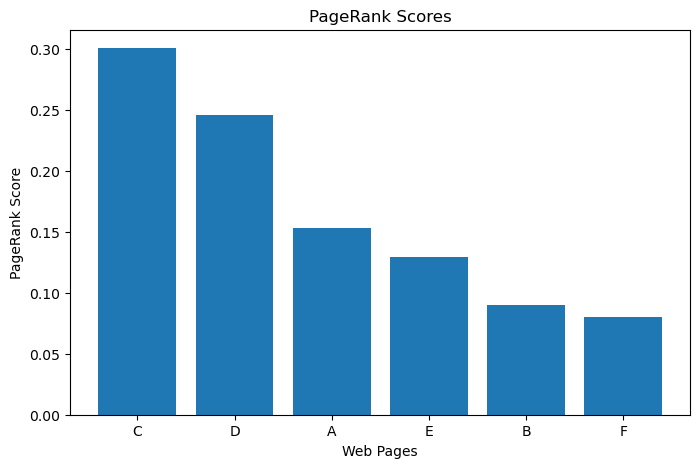

In [6]:
# Visualize PageRank scores

pages = [item[0] for item in ranked_pages]
scores = [item[1] for item in ranked_pages]

plt.figure(figsize=(8, 5))
plt.bar(pages, scores)
plt.xlabel("Web Pages")
plt.ylabel("PageRank Score")
plt.title("PageRank Scores")
plt.show()

## Result

The PageRank score represents the relative importance of each page in the given directed graph. A page receiving important incoming links generally obtains a higher PageRank score.

The PageRank values form a probability distribution, therefore their sum is approximately **1**.

## Conclusion

Thus, the **PageRank algorithm** was implemented successfully using Python and NetworkX. The PageRank values of the pages in the given directed graph were calculated and the pages were ranked according to their importance.